# 02 Shuffling-Varianten

Dieses Notebook zeigt, was die vier Varianten mit der Reihenfolge der Trainingsdaten machen, prüft die Implementierung auf echten Daten und vergleicht A und C in einem kurzen Training.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from matplotlib.colors import ListedColormap

from batch_shuffling_regularization.data import load_mnist
from batch_shuffling_regularization.model import build_mlp
from batch_shuffling_regularization.shuffling import VARIANTS
from batch_shuffling_regularization.training import TrainConfig, make_deterministic, train

make_deterministic()
device = torch.device("cuda")

## Die Varianten

Ausgangspunkt ist immer dieselbe feste Aufteilung des Trainingssets in Batches (Datenpunkt 0-99 in Batch 1, 100-199 in Batch 2, ...). Die Varianten unterscheiden sich darin, was davon sich von Epoche zu Epoche ändert.

| Variante | Funktion in `shuffling.py` | Was passiert vor jeder Epoche | Batch-Zusammensetzung | Reihenfolge der Batches | Reihenfolge im Batch |
|---|---|---|---|---|---|
| A | `no_shuffle` | nichts, immer die Original-Reihenfolge | fest | fest | fest |
| B | `shuffle_batch_order` | die festen Batches werden in eine neue Reihenfolge gebracht | fest | neu | fest |
| C | `shuffle_within_batches` | innerhalb jedes Batches werden die Datenpunkte gemischt | fest | fest | neu |
| D | `full_reshuffle` | der ganze Datensatz wird gemischt, dann neu in Batches geschnitten | neu | neu | neu |

Zwei Folgerungen:

- **C ist mathematisch dasselbe wie A.** Der Gradient eines Batches ist der Mittelwert über seine Datenpunkte, und der hängt nicht von deren Reihenfolge ab. Unterschiede entstehen nur durch Rundung bei der Gleitkomma-Summation. C dient deshalb als Kontrolle.
- **B und C zusammen sind dasselbe wie B.** Nur D erzeugt in jeder Epoche neue Batches.

## Visualisierung an einem Mini-Datensatz

20 Datenpunkte, Batchgröße 4, also 5 Schritte pro Epoche. Jede Zeile ist ein Trainingsschritt, die Zahl ist der Index des Datenpunkts. Die Farbe zeigt, zu welchem Batch der Datenpunkt in der Original-Aufteilung gehört.

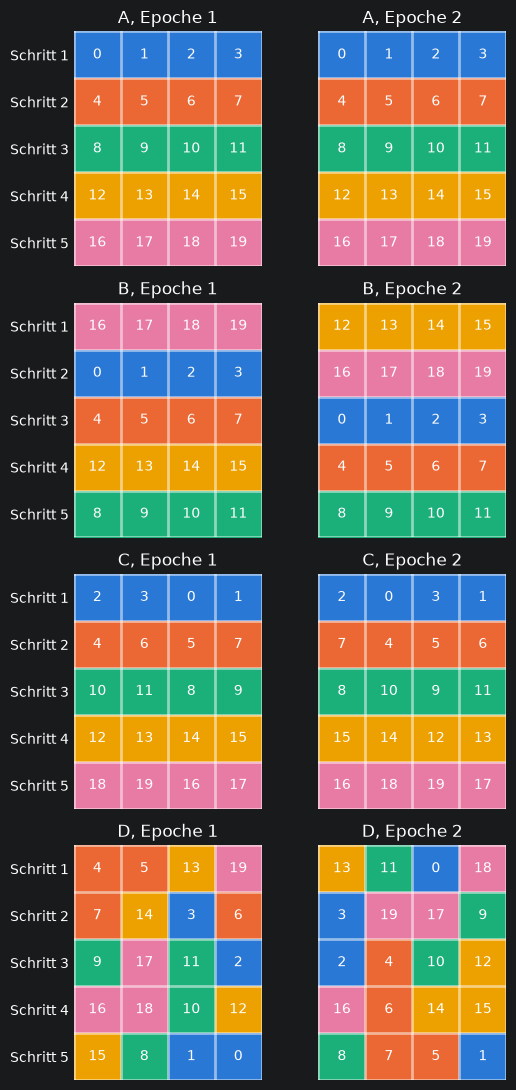

In [2]:
toy_n, toy_bs = 20, 4
cmap = ListedColormap(["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"])

fig, axes = plt.subplots(len(VARIANTS), 2, figsize=(6, 11))
for row, (name, batch_order) in enumerate(VARIANTS.items()):
    gen = torch.Generator().manual_seed(0)
    for epoch in range(2):
        order = batch_order(toy_n, toy_bs, gen)
        n_steps = order.shape[0]
        ax = axes[row, epoch]
        ax.imshow(order // toy_bs, cmap=cmap, vmin=0, vmax=toy_n // toy_bs - 1)
        for step in range(n_steps):
            for pos in range(toy_bs):
                ax.text(pos, step, order[step, pos].item(), ha="center", va="center", fontsize=10)
        ax.set_xticks([x - 0.5 for x in range(toy_bs + 1)], minor=True)
        ax.set_yticks([y - 0.5 for y in range(n_steps + 1)], minor=True)
        ax.grid(which="minor", color="white", lw=2)
        ax.tick_params(which="both", length=0)
        ax.set_xticks([])
        ax.set_yticks(range(n_steps), [f"Schritt {s + 1}" for s in range(n_steps)] if epoch == 0 else [])
        ax.set_title(f"{name}, Epoche {epoch + 1}")
        for spine in ax.spines.values():
            spine.set_visible(False)
plt.tight_layout()

So liest man das Bild:

- **A**: beide Epochen sind identisch.
- **B**: jede Zeile ist einfarbig, die Batches bleiben also erhalten. Nur die Reihenfolge der Zeilen ändert sich.
- **C**: Zeilen und Farben stehen wie bei A, nur die Zahlen innerhalb einer Zeile tauschen die Plätze.
- **D**: die Farben sind gemischt, jeder Batch enthält Datenpunkte aus verschiedenen Original-Batches, und in Epoche 2 sieht es wieder anders aus.

## Prüfung auf den echten Trainingsdaten

50.000 Datenpunkte, Batchgröße 100. Für jede Variante werden zwei Epochen erzeugt und verglichen:

- **Permutation**: jede Epoche enthält jeden Datenpunkt genau einmal.
- **Batches erhalten**: Anteil der Batches in Epoche 2, die (als Menge) schon in Epoche 1 vorkamen.
- **Batch an gleicher Stelle**: Anteil der Schritte, in denen derselbe Batch an derselben Position steht.
- **Index an gleicher Stelle**: Anteil der Einträge, die exakt gleich sind.

In [3]:
n, batch_size = 50_000, 100

def batch_sets(order: torch.Tensor) -> list[tuple[int, ...]]:
    return [tuple(row) for row in order.sort(dim=1).values.tolist()]

rows = []
for name, batch_order in VARIANTS.items():
    gen = torch.Generator().manual_seed(0)
    epoch_1 = batch_order(n, batch_size, gen)
    epoch_2 = batch_order(n, batch_size, gen)
    sets_1, sets_2 = batch_sets(epoch_1), batch_sets(epoch_2)
    rows.append({
        "Variante": name,
        "Permutation": all(torch.equal(e.flatten().sort().values, torch.arange(n)) for e in (epoch_1, epoch_2)),
        "Batches erhalten": sum(s in set(sets_1) for s in sets_2) / len(sets_2),
        "Batch an gleicher Stelle": sum(a == b for a, b in zip(sets_1, sets_2)) / len(sets_2),
        "Index an gleicher Stelle": (epoch_1 == epoch_2).float().mean().item(),
    })
pd.DataFrame(rows).set_index("Variante").round(4)

,Permutation,Batches erhalten,Batch an gleicher Stelle,Index an gleicher Stelle
Variante,,,,
A,True,1.0,1.000,1.0000
B,True,1.0,0.002,0.0020
C,True,1.0,1.000,0.0092
D,True,0.0,0.000,0.0000


Erwartung: A überall 1. B erhält alle Batches, aber kaum einer steht an derselben Stelle. C erhält Batches und deren Position, aber nur ca. 1 % der Einträge (1/Batchgröße) bleibt zufällig auf seinem Platz. D erhält praktisch nichts.

## Kontrolle: Ist C wirklich gleich A?

Drei Trainingsläufe mit identischer Initialisierung (Seed 0), 30 Epochen: A, C und zum Vergleich D. Wenn die Überlegung oben stimmt, sollte der Abstand zwischen A und C deutlich kleiner sein als der zwischen A und D.

In [4]:
data = load_mnist(device)
cfg = TrainConfig()
runs = {name: train(build_mlp(seed=0, device=device), data, VARIANTS[name], cfg, order_seed=0) for name in ["A", "C", "D"]}

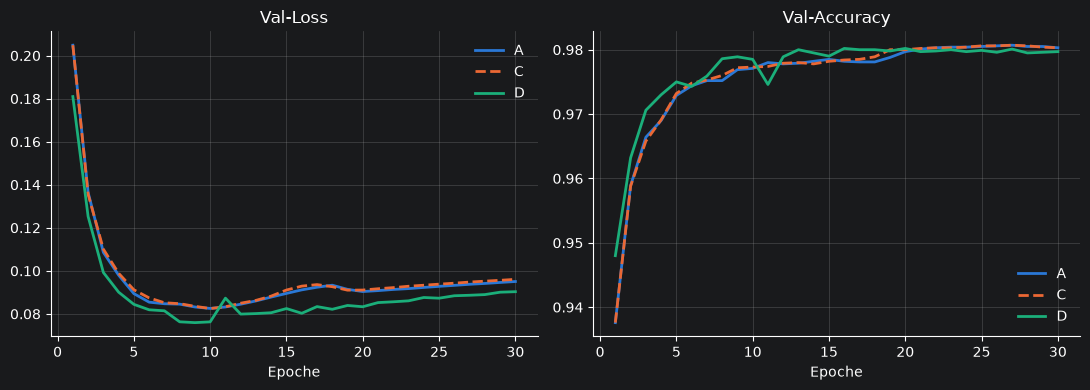

In [5]:
colors = {"A": "#2a78d6", "C": "#eb6834", "D": "#1baf7a"}
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
for name, history in runs.items():
    style = "--" if name == "C" else "-"
    ax_loss.plot(history.index[1:], history["val_loss"].iloc[1:], style, color=colors[name], lw=2, label=name)
    ax_acc.plot(history.index[1:], history["val_acc"].iloc[1:], style, color=colors[name], lw=2, label=name)
ax_loss.set(title="Val-Loss", xlabel="Epoche")
ax_acc.set(title="Val-Accuracy", xlabel="Epoche")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()

In [6]:
metrics = ["train_loss", "val_loss", "val_acc", "test_acc"]
pd.DataFrame({
    "max |C - A|": (runs["C"][metrics] - runs["A"][metrics]).abs().max(),
    "max |D - A|": (runs["D"][metrics] - runs["A"][metrics]).abs().max(),
})

,max |C - A|,max |D - A|
train_loss,0.001345,0.027002
val_loss,0.001981,0.023862
val_acc,0.001200,0.010400
test_acc,0.001200,0.011600
